# Breast Cancer Diagnostic Project

**Intern ID:** CITS9882  
**Full Name:** pasupuleti krishnakamalika  
**No. of Weeks:** 12 weeks  

In [1]:
import os
import pandas as pd
from sklearn.datasets import load_breast_cancer

# Try loading from local CSV, fallback to scikit-learn dataset
csv_path = 'data/data.csv'

if os.path.exists(csv_path):
    print(f"Loading dataset from local path: {csv_path}")
    df = pd.read_csv(csv_path)
else:
    print("Local CSV not found. Loading Breast Cancer dataset from scikit-learn...")
    data = load_breast_cancer()
    df = pd.DataFrame(data.data, columns=data.feature_names)
    df['target'] = data.target

display(df.head())

Local CSV not found. Loading Breast Cancer dataset from scikit-learn...


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


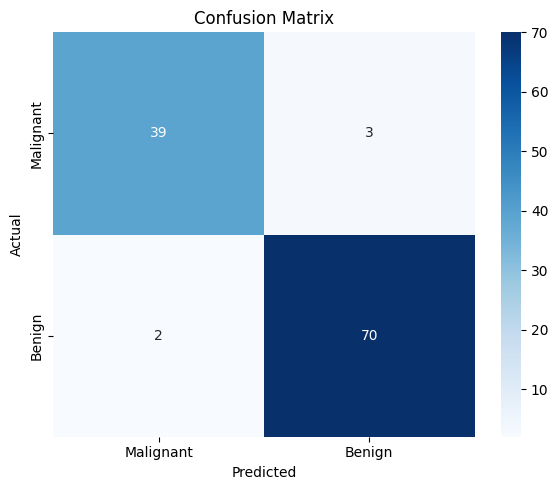

Execution complete!
Saved: images/confusion_matrix.png
Saved: models/breast_cancer_rf_model.pkl
Saved: model_results.csv


,Metric,Value
0,Accuracy,0.956140
1,Precision (Benign),0.958904
2,Recall (Benign),0.972222
3,F1-Score (Benign),0.965517


In [2]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Create required output directories
os.makedirs('images', exist_ok=True)
os.makedirs('models', exist_ok=True)

# Prepare features and targets
X = df.drop(columns=['target'])
y = df['target']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Initialize and train the Random Forest model
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Generate and save a confusion matrix plot
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Malignant', 'Benign'], yticklabels=['Malignant', 'Benign'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig('images/confusion_matrix.png')
plt.show()

# Compute accuracy metrics
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, output_dict=True)

# Export results to CSV
results_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision (Benign)', 'Recall (Benign)', 'F1-Score (Benign)'],
    'Value': [accuracy, report['1']['precision'], report['1']['recall'], report['1']['f1-score']]
})
results_df.to_csv('model_results.csv', index=False)

# Save the model artifact
joblib.dump(model, 'models/breast_cancer_rf_model.pkl')

print("Execution complete!")
print("Saved: images/confusion_matrix.png")
print("Saved: models/breast_cancer_rf_model.pkl")
print("Saved: model_results.csv")
display(results_df)

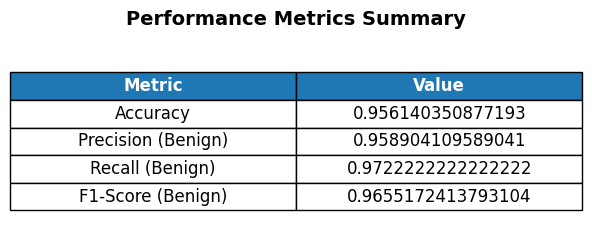

In [3]:
import matplotlib.pyplot as plt

# Create a visually clean table plot for screenshots
fig, ax = plt.subplots(figsize=(6, 2.5))
ax.axis('off')
ax.axis('tight')

# Create the table representation
table = ax.table(cellText=results_df.values, colLabels=results_df.columns, loc='center', cellLoc='center')

# Style the table
table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1.2, 1.8)

# Format header row specifically
for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_text_props(weight='bold', color='white')
        cell.set_facecolor('#1f77b4')

plt.title('Performance Metrics Summary', fontsize=14, weight='bold', pad=20)
plt.tight_layout()
plt.savefig('images/performance_metrics.png', dpi=300)
plt.show()